# Completed survey: reproducible descriptive analysis

This notebook applies the **same questionnaire validation and scoring** to the human export and a separate fictional fixture. The private export is read from `data/raw/survey_export.csv.zip` when present; it is ignored by Git. Only aggregate results are displayed. Synthetic responses are never pooled with real responses or treated as study participants. Recruitment and response collection took place on 3–4 November 2026, and the study owner confirmed that collection is closed at five real responses.


In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(ROOT / ".cache"))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
import json
from src.analyze_survey import analyze

CONFIG = json.loads((ROOT / "config.json").read_text(encoding="utf-8"))
REAL_EXPORT = ROOT / "data" / "raw" / "survey_export.csv.zip"
SYNTHETIC_EXPORT = ROOT / "data" / "sample" / "completed_survey_synthetic_75.csv"
print("Real export available locally:", REAL_EXPORT.exists())
print("Synthetic fixture available:", SYNTHETIC_EXPORT.exists())


Real export available locally: True
Synthetic fixture available: True


## 1. Ingest and validate

The shared parser checks eligibility, required answers, ranges, and the four-option adapted CBI scoring. The original ZIP is not modified. Unusual values are review flags, not automatic exclusions. If the private export is absent, the public notebook still runs the synthetic demonstration.


In [2]:
synthetic_report = analyze(SYNTHETIC_EXPORT, CONFIG, origin="synthetic")
real_report = analyze(REAL_EXPORT, CONFIG, origin="real") if REAL_EXPORT.exists() else None
reports = [report for report in (real_report, synthetic_report) if report is not None]
quality = pd.DataFrame([
    {
        "Origin": report["origin"],
        "Input": report["n_input"],
        "Eligible": report["n_eligible"],
        "Valid": report["n_valid"],
        "Rejected": report["n_rejected"],
        "Eligibility exclusions": report["n_excluded_eligibility"],
        "Review flags": sum(report["review_flags"].values()),
    }
    for report in reports
])
display(quality)


,Origin,Input,Eligible,Valid,Rejected,Eligibility exclusions,Review flags
0,real,5,5,5,0,0,2
1,synthetic,75,75,75,0,0,0


## 2. Score and summarize outcomes

PSS-10 reverses items 4, 5, 7, and 8. The administered CBI form offered **four** combined responses scored 0, 25, 75, and 100, with item 7 reversed. The CBI result is therefore an **adapted work score**, not the original five-category scale. The table uses sample SD (`ddof=1`) and preserves each group's origin. SD describes spread among observed answers; it is not a confidence interval.


In [3]:
METRICS = (
    ("pss_score", "PSS-10", "points", (0, 40)),
    ("adapted_cbi_work_score", "Adapted CBI work", "points", (0, 100)),
    ("productivity_0_10", "Self-rated productivity", "points", (0, 10)),
)
summary_rows = []
for report in reports:
    for key, label, unit, bounds in METRICS:
        item = report["descriptive"][key]
        summary_rows.append({
            "Origin": report["origin"], "Metric": label, "n": item["n"],
            "Mean": item["mean"], "SD": item["sd"],
            "Median": item["median"], "Min": item["min"], "Max": item["max"],
            "Unit": unit,
        })
summary = pd.DataFrame(summary_rows)
display(summary)


,Origin,Metric,n,Mean,SD,Median,Min,Max,Unit
0,real,PSS-10,5,18.200,2.683,17.000,16.000000,22.000000,points
1,real,Adapted CBI work,5,23.571,13.025,17.857,10.714286,39.285714,points
2,real,Self-rated productivity,5,7.400,2.191,8.000,4.000000,10.000000,points
3,synthetic,PSS-10,75,21.280,4.964,21.000,11.000000,33.000000,points
4,synthetic,Adapted CBI work,75,50.857,14.065,53.571,17.857143,82.142857,points
5,synthetic,Self-rated productivity,75,5.467,2.929,5.000,0.000000,10.000000,points


## 3. Categorical communication

The questionnaire records ordered categories. Counts are shown as recorded; categories are not converted into exact contacts per week.


In [4]:
communication = pd.DataFrame([
    {"Origin": report["origin"], "Category": category, "n": count}
    for report in reports
    for category, count in report.get("communication_frequency", {}).items()
])
display(communication)


,Origin,Category,n
0,real,Несколько раз в день,5
1,synthetic,Реже,13
2,synthetic,Примерно раз в неделю,17
3,synthetic,Несколько раз в неделю,17
4,synthetic,Примерно раз в день,11
5,synthetic,Несколько раз в день,17


## 4. Descriptive figure

Panels have fixed score ranges and display group means with **±1 sample SD**. The blue marks are human responses, and the orange marks are fictional pipeline examples. They are separate sources, so the figure does not test a difference or rank a winner. The comparison figure is saved locally under the ignored `results/figures/` directory. A separate aggregate-only figure for real responses is exported to `reports/figures/` in PDF and 300-DPI PNG.


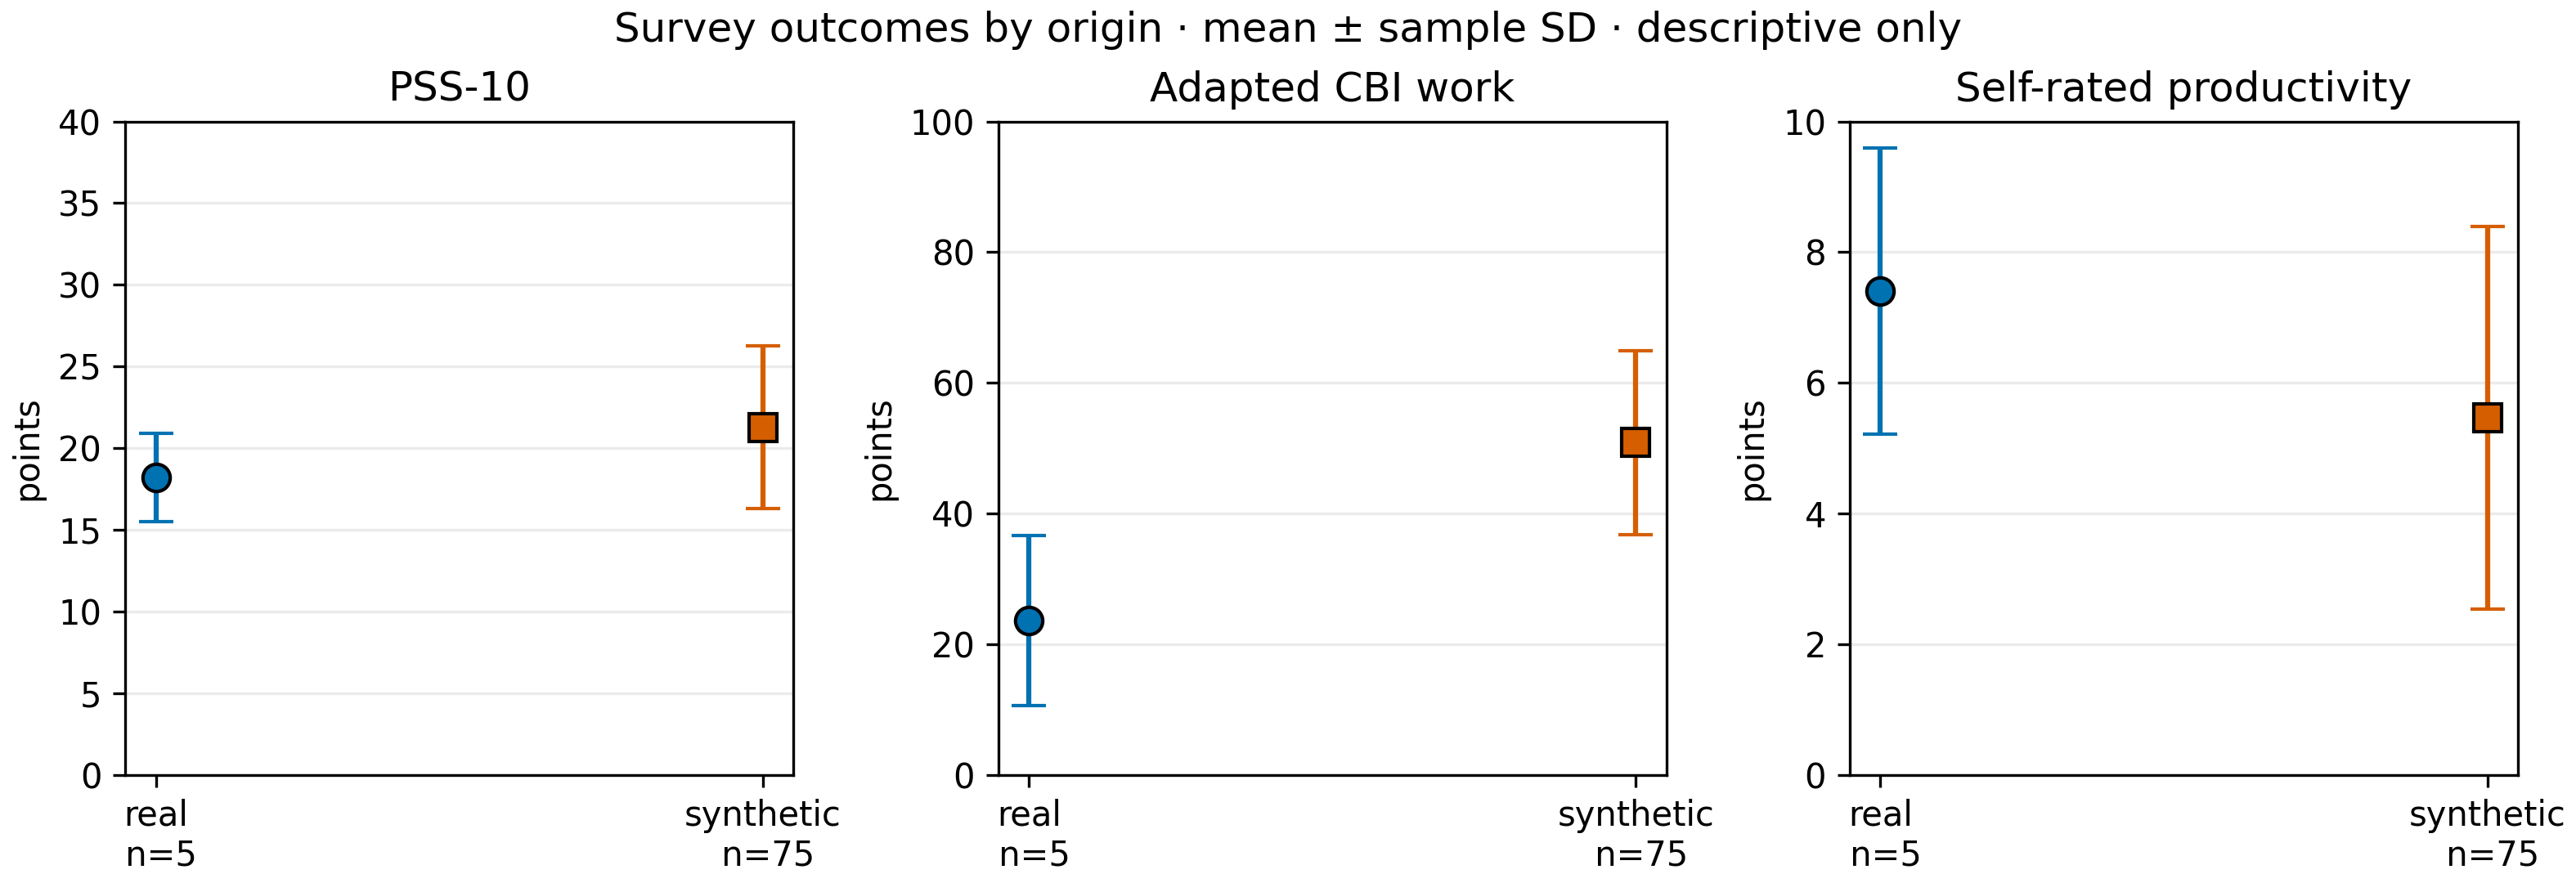

In [5]:
out_dir = ROOT / "results" / "figures"
out_dir.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6), constrained_layout=True)
colors = {"real": "#0072B2", "synthetic": "#D55E00"}
markers = {"real": "o", "synthetic": "s"}
for ax, (key, label, unit, bounds) in zip(axes, METRICS):
    for x, report in enumerate(reports):
        value = report["descriptive"][key]
        origin = report["origin"]
        ax.errorbar(x, value["mean"], yerr=value["sd"], fmt=markers[origin],
                    markersize=8, capsize=5, color=colors[origin],
                    markeredgecolor="black", label=f"{origin} (n={value['n']})")
    ax.set(title=label, ylabel=unit, ylim=bounds,
           xticks=range(len(reports)),
           xticklabels=[f"{r['origin']}\n n={r['n_valid']}" for r in reports])
    ax.grid(axis="y", alpha=.25)
fig.suptitle("Survey outcomes by origin · mean ± sample SD · descriptive only")
fig.savefig(out_dir / "survey_outcomes_by_origin.pdf")
fig.savefig(out_dir / "survey_outcomes_by_origin.png", dpi=300)
plt.close(fig)
display(Image(filename=str(out_dir / "survey_outcomes_by_origin.png")))
if real_report is not None:
    public_dir = ROOT / "reports" / "figures"
    public_dir.mkdir(parents=True, exist_ok=True)
    real_fig, real_axes = plt.subplots(1, 3, figsize=(10.5, 3.6), constrained_layout=True)
    for ax, (key, label, unit, bounds) in zip(real_axes, METRICS):
        value = real_report["descriptive"][key]
        ax.errorbar([0], [value["mean"]], yerr=[value["sd"]], fmt="o",
                    markersize=8, capsize=5, color="#0072B2", markeredgecolor="black")
        ax.set(title=label, ylabel=unit, ylim=bounds, xlim=(-0.5, 0.5),
               xticks=[0], xticklabels=[f"Real responses\n n={value['n']}"])
        ax.grid(axis="y", alpha=.25)
    real_fig.suptitle("Observed survey outcomes · mean ± sample SD · descriptive only")
    real_fig.savefig(public_dir / "real_survey_outcomes.pdf")
    real_fig.savefig(public_dir / "real_survey_outcomes.png", dpi=300)
    plt.close(real_fig)


## 5. Interpretation boundary and refresh

The final human export contains five valid questionnaires from former colleagues and friends, collected on 3–4 November 2026. The study owner confirmed that no more responses are expected. Both review-flagged answers are retained as reported. Report descriptive values and data-quality checks, but do not estimate RQ1–RQ3 hypothesis tests or combine them with the 75 synthetic records. The 80-case code gate applies to real complete cases: five real plus 75 fictional rows do not satisfy it. The report states the recruitment period, sample size, missingness, adapted CBI wording, and limits on generalization.
